# Newton's Method: Golden Ratio
Thank you, Miles Waugh!


## Background and History

I want to introduce you to the golden ratio, but if you are not interested in the background: _you can safely skip this section_.

The golden ratio, which we denote by $\phi = \displaystyle \frac{1 + \sqrt{5}}{2}$, dates back to ancient Greek mathematics (although they did not call it the "golden ratio"). Although some historians suspect earlier awareness among the Pythagoreans, the quantity appears for the first time definitively in Euclid's _Elements_ as the solution to the problem of dividing a line segment into two parts such that the ratio of the whole segment to the larger part is equal to the ratio of the larger part to the smaller part (this ratio is what we now call the golden ratio). Greek mathematicians discovered that this proportion naturally appears in regular pentagons and pentagrams. Because of this, the ratio was studied heavily in classical geometry.

The golden ratio is part of a set of so-called **constructible numbers** because, given a line segment of unit length, we can construct a line segment of length $\phi$ using only a compass and straightedge in a finite number of steps. It turns out that all rational numbers are constructible, but not all constructible numbers are rational.

I will not prove this here, but the golden ratio is an irrational number; it therefore has an infinite number of digits in its decimal expansion, which are unpredictable (like $\pi$). An interesting question is then how one may compute the value of $\phi$ to a high degree of accuracy. To provide insight into how a computer might compute $\phi$ to many digits at a fundamental level, we will restrict ourselves to only using addition, subtraction, and multiplication (any more complicated functions would be implemented using these more basic operations anyway).

A very efficient way to compute the golden ratio using only addition, subtraction, and multiplication is to use Newton's method. The golden ratio is the positive root of the function
$$f\left(x\right)=\frac{1}{\left(2x-1\right)^{2}}-0.2.$$

## Your Task

1. Write a function that implements Newton's method for the function  
   $$f(x)=\frac{1}{(2x-1)^2}-0.2.$$

    First compute the derivative $f'(x)$, then derive the Newton update
    $$x_{n+1} = x_n - \frac{f(x_n)}{f'(x_n)}.$$

    Simplify your expression so that the iteration $g(x_n)$ contains **no division operations** and is written as a polynomial in $x_n$. Implement this iteration as a Python function.

2. Choose an initial guess $x_0 = 1$. Use your function to compute the first 8 Newton iterates
   $$x_0, x_1, x_2, \dots, x_{10}.$$

    Print these values. What number do the iterates appear to approach? Do they numbers stop changing after a while (they "converge")? If so, at what iteration do they converge?

3. Store the iterates in a list or NumPy array and create a plot of the values $x_n$ versus the iteration number $n$. Does the sequence appear to converge quickly?

4. Use the final iterate you computed as your best approximation of the golden ratio. Compute the error at each iteration
   $$e_n = |x_n - x_{10}|.$$

    Plot the error $e_n$ versus $n$.

5. Create a semilog plot of the error using `plt.semilogy`. What do you notice about how quickly the error decreases as the iteration proceeds?

6. (Optional challenge) Compute the quantity
   $$\frac{e_{n+1}}{e_n^2}$$
   for several iterations. Do these values appear to approach a constant?


## SOLUTION

### Part 1: Implement the Newton iteration

You should find that
$$f'(x)=\frac{4}{(1-2x)^{3}},$$
and therefore the Newton iteration is
$$g\left(x_n\right)=-\frac{2}{5}x_n^{3}+\frac{3}{5}x_n^{2}+\frac{6}{5}x_n-\frac{1}{5}=0.2\left(x_n((3-2x_n)x_n+6)-1\right),$$
where I have written the polynomial in Horner form (also called Horner's scheme or Horner's method) as it is the most efficient way to evaluate it. Horner attributed the method to Joseph-Louis Lagrange, but it was known to Chinese and Persian mathematicians as early as the 13th century.


In [2]:
def newton_step(x: float) -> float:
    return 0.2 * (x * (x * (3 - 2 * x) + 6) - 1)

### Part 2: Compute the first 10 iterates

In [5]:
x = 1.0
iterates: list[float] = [x]

for _ in range(10):
    x = newton_step(x)
    iterates.append(x)

for i, val in enumerate(iterates):
    print(f"x_{i} =", val)

x_0 = 1.0
x_1 = 1.2000000000000002
x_2 = 1.4128
x_3 = 1.5649806139392002
x_4 = 1.6143174562142786
x_5 = 1.6180154777174776
x_6 = 1.618033988290173
x_7 = 1.618033988749895
x_8 = 1.618033988749895
x_9 = 1.618033988749895
x_10 = 1.618033988749895


The iterates appear to approach the value $1.618033988749895$, converging after just 7 iterations.


### Part 3: Plot the iterates

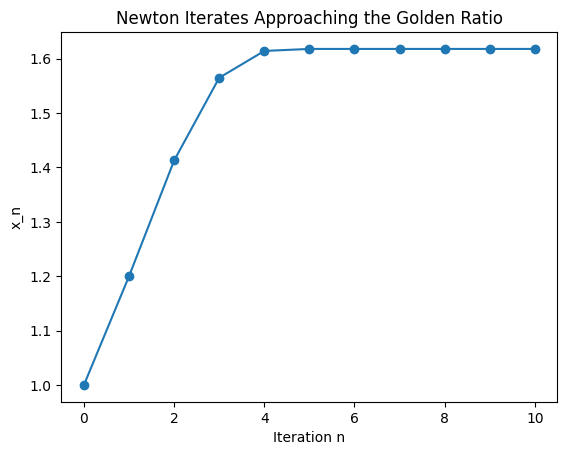

In [3]:
import matplotlib.pyplot as plt

n: list[int] = list(range(len(iterates)))

plt.plot(n, iterates, marker="o")
plt.xlabel("Iteration n")
plt.ylabel("x_n")
plt.title("Newton Iterates Approaching the Golden Ratio")
plt.show()

The plot of $x_n$ versus $n$ shows that the sequence converges very quickly. After only a few iterations, the values are already very close together.

### Part 4: Plot the errors

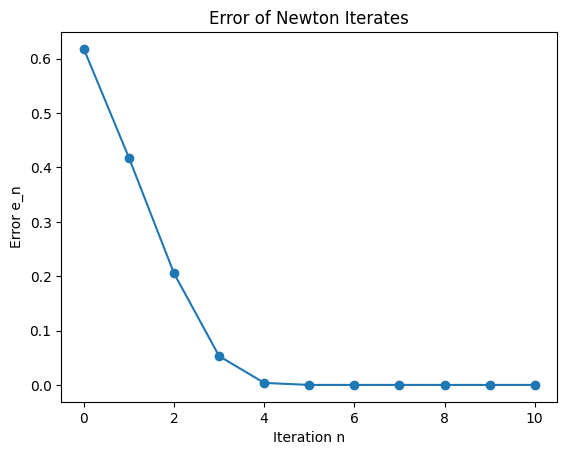

In [4]:
approx_phi = iterates[-1]

errors: list[float] = [abs(x - approx_phi) for x in iterates]

plt.plot(n, errors, marker="o")
plt.xlabel("Iteration n")
plt.ylabel("Error e_n")
plt.title("Error of Newton Iterates")
plt.show()

The error decreases rapidly toward $0$ as the iteration number increases. Interestingly, it seems to decrease linearly at first even though I know asymptotically that it should decrease quadratically (in the limit as the number of iterations and correct digits goes to infinity).


### Part 5: Semilog plot of the errors

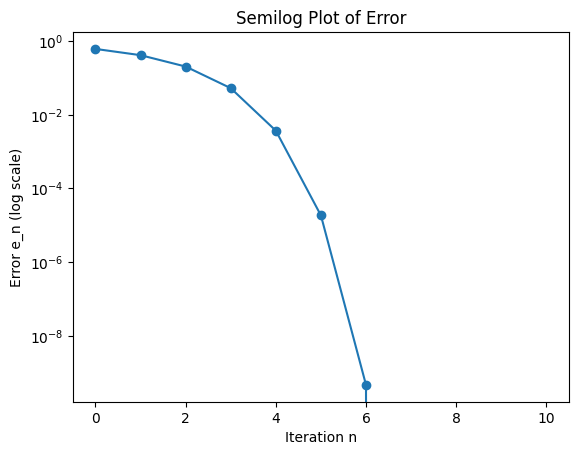

In [5]:
plt.semilogy(n, errors, marker="o")
plt.xlabel("Iteration n")
plt.ylabel("Error e_n (log scale)")
plt.title("Semilog Plot of Error")
plt.show()

On the semilog plot, the error drops very steeply after the first few iterations. This shows that Newton's method is converging very quickly for this problem!


### Part 6 (optional): Compute the ratios

In [6]:
ratios: list[float] = []

for i in range(len(errors) - 1):
    if errors[i] != 0:
        ratios.append(errors[i + 1] / errors[i] ** 2)

for i, r in enumerate(ratios):
    print(f"ratio_{i} =", r)

ratio_0 = 1.0944271909999155
ratio_1 = 1.1744271909999167
ratio_2 = 1.259547190999913
ratio_3 = 1.3204194365757131
ratio_4 = 1.3401541734980003
ratio_5 = 1.341633305794688
ratio_6 = 0.0


The students DO NOT need to know what order of convergence means at all, but I've included this here for completeness. A perfectly acceptable answer for this part could be "the values appear to approach a constant, approximately $1.34164$."

---

**Definition (Quadratic Convergence).**

Let $\{x_n\}$ be a sequence that converges to a value $x^\ast$. We say that the sequence converges with **order $2$** (or **quadratically**) if there exists a constant $C>0$ such that

$$
\lim_{n\to\infty} \frac{|x_{n+1}-x^\ast|}{|x_n-x^\ast|^2} = C.
$$

In other words, for $n$ sufficiently large the errors $e_n = |x_n - x^\ast|$ satisfy approximately

$$
e_{n+1} \approx C\,e_n^2.
$$

---

The values of
$$\frac{e_{n+1}}{e_n^2}$$
appear to approach a constant, approximately $1.34164$.

This supports the fact thats the Newton iteration converges quadratically. The final value $0.0$ is due to floating-point roundoff: at that stage the computed error is so small that it is recorded as exactly zero on the computer.
